### Initialization
Add the Surrogate Modeling module and setup the notebook

In [5]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
!
print(module_path)


c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels


### Cokriging Forrester 2007 Recreation

Use the cokriging model class to recreate the Forrester paper example with a fixed scaling factor.

Optimization terminated successfully.
         Current function value: -56.956359
         Iterations: 21
         Function evaluations: 43
[18.42120361]
Optimization terminated successfully.
         Current function value: 3.289332
         Iterations: 18
         Function evaluations: 36
Optimization terminated successfully.
         Current function value: 11.254340
         Iterations: 32
         Function evaluations: 86
[1062.]


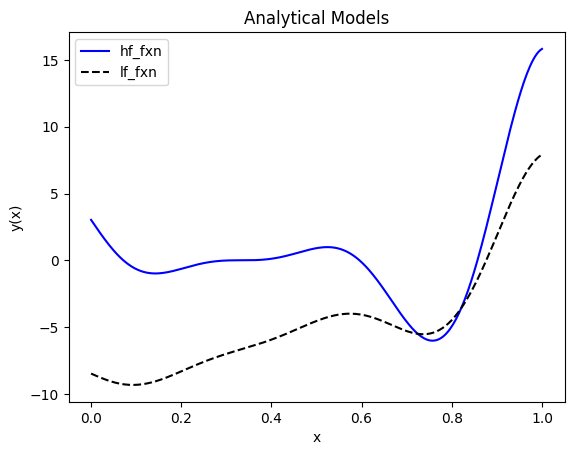

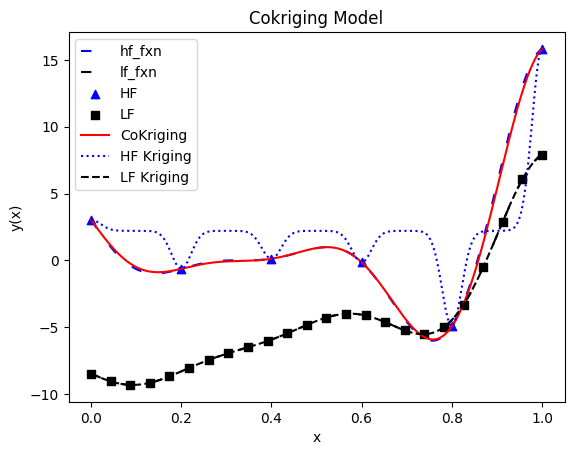

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import mfs_functions, cokriging

# Start with a synthetic dataset
rng = np.random.RandomState(0)
fxn_ind = 1
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n_lf = 30
n_hf = 6

x_lf = np.zeros((n_lf,dim), dtype=float)
x_hf = np.zeros((n_hf,dim), dtype=float)

# Generate the analytical functions
hf_fxn = mfs_functions.expensive_fxn(1)
lf_fxn = mfs_functions.cheap_fxn(1)


x_lf[:,0] = np.linspace(xmin,xmax,n_lf)
y_lf = lf_fxn.evaluate(x_lf)
x_hf[:,0] = np.linspace(xmin,xmax,n_hf)
y_hf = hf_fxn.evaluate(x_hf)
model = cokriging.CoKriging(x_lf,y_lf,x_hf,y_hf,True)

x_vals = np.zeros((300,1))
x_vals[:,0] = np.linspace(0,1,300)

#plot the model information
plot_name = "Analytical Models"    
hf_fxn.plot_model(x_vals, plot_name, color = "blue",
                  linestyle = 'solid', label = "hf_fxn")
lf_fxn.plot_model(x_vals, plot_name, color = "black",
                  linestyle = 'dashed', label = "lf_fxn")

plot_name = "Cokriging Model"
hf_fxn.plot_model(x_vals,plot_name, color = "blue",
                  linestyle = (0, (5, 10)), label = "hf_fxn")
lf_fxn.plot_model(x_vals,plot_name, color = "black",
                  linestyle = (0, (5, 10)), label = "lf_fxn")
model.plot_data(plot_name, color_lf="black", color_hf="blue", 
                label_hf = "HF", label_lf = "LF",
                marker_hf = '^',marker_lf="s")
model.plot_model(x_vals,name=plot_name,color="red",
                   label = "CoKriging", linestyle='solid')
model.kriging_hf.plot_model(x_vals, name=plot_name, color="blue",
                    label = "HF Kriging", linestyle='dotted')
model.kriging_lf.plot_model(x_vals, name=plot_name, color="black",
                    label = "LF Kriging", linestyle='dashed')
plt.show()

### Cokriging LF Sample size change

Test the cokriging formulation on different sample sizes to test stability.

Optimization terminated successfully.
         Current function value: -33.592468
         Iterations: 23
         Function evaluations: 46
[4.02618408]
Optimization terminated successfully.
         Current function value: -1.954852
         Iterations: 29
         Function evaluations: 78
[422.]


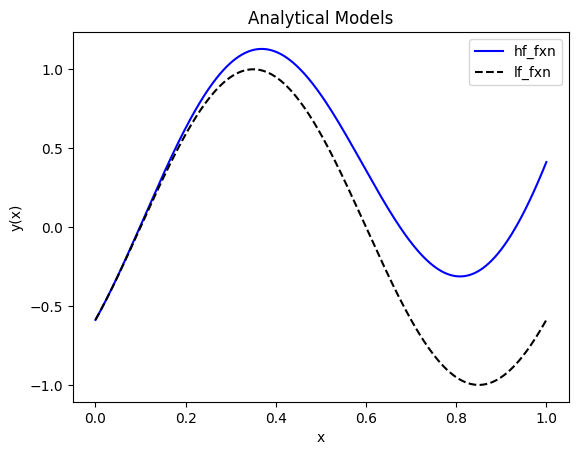

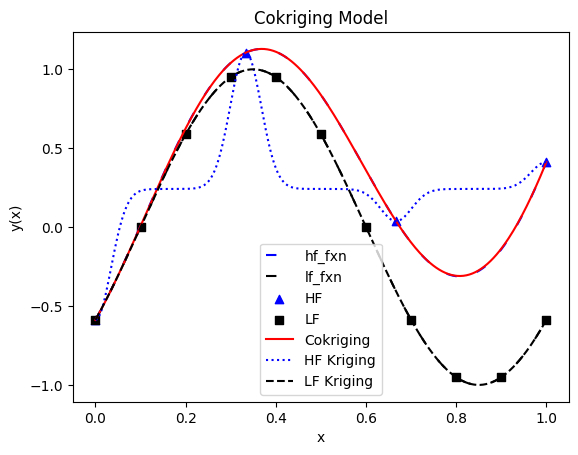

In [7]:
# Start with a synthetic dataset
rng = np.random.RandomState(0)
fxn_ind = 2
dim, xmin, xmax = mfs_functions.function_bounds(fxn_ind)

n_lf = 11
n_hf = 4

x_lf = np.zeros((n_lf, dim), dtype=float)
x_hf = np.zeros((n_hf, dim), dtype=float)

# Generate the analytical functions
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)


x_lf[:, 0] = np.linspace(xmin, xmax, n_lf)
y_lf = lf_fxn.evaluate(x_lf)
x_hf[:, 0] = np.linspace(xmin, xmax, n_hf)
y_hf = hf_fxn.evaluate(x_hf)
model = cokriging.CoKriging(x_lf, y_lf, x_hf, y_hf)

x_vals = np.ones((300, 1))
x_vals[:, 0] = np.linspace(0, 1, 300)

# plot the model information
plot_name = "Analytical Models"
hf_fxn.plot_model(x_vals, plot_name, color="blue", linestyle="solid", label="hf_fxn")
lf_fxn.plot_model(x_vals, plot_name, color="black", linestyle="dashed", label="lf_fxn")

plot_name = "Cokriging Model"
hf_fxn.plot_model(
    x_vals, plot_name, color="blue", linestyle=(0, (5, 10)), label="hf_fxn"
)
lf_fxn.plot_model(
    x_vals, plot_name, color="black", linestyle=(0, (5, 10)), label="lf_fxn"
)
model.plot_data(
    plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
)
model.plot_model(
    x_vals, name=plot_name, color="red", label="Cokriging", linestyle="solid"
)
model.kriging_hf.plot_model(
    x_vals, name=plot_name, color="blue", label="HF Kriging", linestyle="dotted"
)
model.kriging_lf.plot_model(
    x_vals, name=plot_name, color="black", label="LF Kriging", linestyle="dashed"
)
plt.show()

### 3 Dimensional Dataset

Run Cokriging on 3D dataset (2 input, 1 output)

In [8]:
# Start with a synthetic dataset
rng = np.random.RandomState(0)
fxn_ind = 5
dim, xmin, xmax = mfs_functions.function_bounds(fxn_ind)

n_lf = 11
n_hf = 4

x_lf = np.zeros((n_lf, dim), dtype=float)
x_hf = np.zeros((n_hf, dim), dtype=float)

# Generate the analytical functions
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)


x_lf[:, 0] = np.linspace(xmin, xmax, n_lf)
y_lf = lf_fxn.evaluate(x_lf)
x_hf[:, 0] = np.linspace(xmin, xmax, n_hf)
y_hf = hf_fxn.evaluate(x_hf)
model = cokriging.CoKriging(x_lf, y_lf, x_hf, y_hf)

x_vals = np.ones((300, 1))
x_vals[:, 0] = np.linspace(0, 1, 300)

# plot the model information
plot_name = "Analytical Models"
hf_fxn.plot_model(x_vals, plot_name, color="blue", linestyle="solid", label="hf_fxn")
lf_fxn.plot_model(x_vals, plot_name, color="black", linestyle="dashed", label="lf_fxn")

plot_name = "Cokriging Model"
hf_fxn.plot_model(
    x_vals, plot_name, color="blue", linestyle=(0, (5, 10)), label="hf_fxn"
)
lf_fxn.plot_model(
    x_vals, plot_name, color="black", linestyle=(0, (5, 10)), label="lf_fxn"
)
model.plot_data(
    plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
)
model.plot_model(
    x_vals, name=plot_name, color="red", label="Cokriging", linestyle="solid"
)
model.kriging_hf.plot_model(
    x_vals, name=plot_name, color="blue", label="HF Kriging", linestyle="dotted"
)
model.kriging_lf.plot_model(
    x_vals, name=plot_name, color="black", label="LF Kriging", linestyle="dashed"
)
plt.show()

ValueError: could not broadcast input array from shape (11,2,1) into shape (11,)